# Proyecto Integrador · Pipeline ETL con Zona de Cuarentena
**Ingeniería de Datos (ATD-2602) · Unidad 2 · TecNM Campus Colima**
**Grupo 2 – Fintech & Transacciones Bancarias** · Ingeniera 1 (Calidad, Nulos y Outliers): **Carol Ivette Rodríguez Lepe – 23460709**

## Fase 1 (Diagnóstico de calidad) y Fase 2 (Faltantes e imputación)
Fuentes: `catalogo_cuentas.csv` (Core Bancario), `transacciones_atm.csv` (cajeros), `transferencias_digitales.json` (SPEI / App).

El flujo sigue lo visto en clase: **sesión 22** (nulos disfrazados con `na_values`, completitud ordenada, MCAR/MAR/MNAR, `missingno`), **actividad 3.1.2** (Tukey/IQR vs Z-score), **sesión 26** (`drop_duplicates`, funciones que regresan `.copy()`) y **sesión 28** (`SimpleImputer` con mediana). La lógica vive en `src/`; esta libreta la ejecuta y muestra la evidencia.

In [1]:
import sys, pathlib
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ))
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
from IPython.display import Image, display
from src import config as C, fase1_diagnostico as F1, fase2_imputacion as F2, figuras_ing1 as FIG
C.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 200)
print('pandas', pd.__version__)

pandas 3.0.5


---
# FASE 1 · Diagnóstico de calidad inicial (dato crudo, sin transformar)
### 1.1 Exploración de nulos disfrazados
Igual que en la sesión 22: primero se carga **sin convertir nada a NaN** (`keep_default_na=False, dtype=str`) para ver qué textos significan "no hay dato".

In [2]:
disfrazados = F1.explorar_nulos_disfrazados()
disfrazados

,dataset,columna,valor_encontrado,conteo
0,transacciones_atm,monto_mxn,(vacío),27
1,transacciones_atm,id_cajero,(vacío),44
2,transferencias_digitales,notification_email,(vacío),8
3,transferencias_digitales,notification_email,null,8


> En el JSON hay **8 `null` y 8 cadenas vacías `''`** en `notification_email`. Las vacías **no aparecen en `isna()`**: son nulos disfrazados.
### 1.2 Carga definitiva con `na_values` y tipos seguros

In [3]:
print('NA_VALUES =', C.NA_VALUES)
ingenuo = F1.cargar_crudo_ingenuo()   # carga por defecto: solo para documentar los dtypes que infiere pandas
seguro  = F1.cargar_crudo_seguro()    # carga del pipeline: na_values + identificadores como texto
for k, d in seguro.items():
    print(f'{k:28s} {d.shape[0]:>4} filas x {d.shape[1]} columnas')

NA_VALUES = ['', ' ', 'N/A', 'NA', 'n/a', 'na', 'null', 'NULL', 'None', 'none', '-', '--', '?', 'nan', 'NaN', 'unknown', 'Unknown', 'desconocido', 'S/D']
catalogo_cuentas               50 filas x 6 columnas
transacciones_atm             620 filas x 8 columnas
transferencias_digitales      600 filas x 10 columnas


### 1.3 Tipos inferidos (`dtypes` / `info()`)

In [4]:
ingenuo['transferencias_digitales'].info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transfer_id         600 non-null    str    
 1   timestamp           600 non-null    object 
 2   account_id          600 non-null    str    
 3   amount              600 non-null    float64
 4   currency            600 non-null    str    
 5   beneficiary_clabe   600 non-null    int64  
 6   notification_email  592 non-null    str    
 7   concept             600 non-null    str    
 8   status              600 non-null    str    
 9   platform            600 non-null    str    
dtypes: float64(1), int64(1), object(1), str(7)
memory usage: 47.0+ KB


In [5]:
tipos = F1.comparar_tipos(ingenuo, seguro)
display(tipos[tipos.dtype_carga_por_defecto != tipos.dtype_carga_segura])
# Evidencia: la carga por defecto convierte la CLABE a int64 y pierde el '0' inicial
pd.DataFrame({'CLABE por defecto (int64)': ingenuo['transferencias_digitales']['beneficiary_clabe'].head(3).astype(str),
              'CLABE carga segura (texto)': seguro['transferencias_digitales']['beneficiary_clabe'].head(3)})

,dataset,columna,dtype_carga_por_defecto,dtype_carga_segura
0,catalogo_cuentas,id_cuenta,str,string
6,transacciones_atm,id_transaccion,str,string
8,transacciones_atm,id_cuenta,str,string
11,transacciones_atm,id_cajero,str,string
14,transferencias_digitales,transfer_id,str,string
16,transferencias_digitales,account_id,str,string
18,transferencias_digitales,currency,str,object
19,transferencias_digitales,beneficiary_clabe,int64,string
20,transferencias_digitales,notification_email,str,object
21,transferencias_digitales,concept,str,object


,CLABE por defecto (int64),CLABE carga segura (texto)
0,12210100614023846,012210100614023846
1,12851851854195836,012851851854195836
2,12842918353119961,012842918353119961


### 1.4 Completitud: nulos por columna y % de completitud, de menor a mayor (3 más críticas)

In [6]:
perfil_cols, perfil_res = F1.perfil_completo(ingenuo)
F1.ranking_completitud(perfil_cols).head(8)

,dataset,columna,total_ausentes,pct_nulos,pct_completitud,critica
0,transacciones_atm,id_cajero,44,7.10,92.90,SÍ
1,transacciones_atm,monto_mxn,27,4.35,95.65,SÍ
2,transferencias_digitales,notification_email,16,2.67,97.33,SÍ
3,catalogo_cuentas,estado_cuenta,0,0.00,100.00,
4,catalogo_cuentas,fecha_apertura,0,0.00,100.00,
5,catalogo_cuentas,id_cuenta,0,0.00,100.00,
6,catalogo_cuentas,limite_credito_mxn,0,0.00,100.00,
7,catalogo_cuentas,tipo_cuenta,0,0.00,100.00,


In [7]:
perfil_cols[['dataset','columna','dtype_inferido','tipos_python','nulos_explicitos','nulos_ocultos','pct_nulos','pct_completitud','n_unicos','pct_unicidad']]

,dataset,columna,dtype_inferido,tipos_python,nulos_explicitos,nulos_ocultos,pct_nulos,pct_completitud,n_unicos,pct_unicidad
0,catalogo_cuentas,id_cuenta,str,str:50,0,0,0.00,100.00,50,100.00
1,catalogo_cuentas,titular,str,str:50,0,0,0.00,100.00,49,98.00
2,catalogo_cuentas,tipo_cuenta,str,str:50,0,0,0.00,100.00,5,10.00
3,catalogo_cuentas,limite_credito_mxn,float64,float:50,0,0,0.00,100.00,5,10.00
4,catalogo_cuentas,fecha_apertura,str,str:50,0,0,0.00,100.00,50,100.00
5,catalogo_cuentas,estado_cuenta,str,str:50,0,0,0.00,100.00,3,6.00
6,transacciones_atm,id_transaccion,str,str:620,0,0,0.00,100.00,600,96.77
7,transacciones_atm,fecha_hora,str,str:620,0,0,0.00,100.00,600,96.77
8,transacciones_atm,id_cuenta,str,str:620,0,0,0.00,100.00,82,13.23
9,transacciones_atm,tipo_operacion,str,str:620,0,0,0.00,100.00,4,0.65


### 1.5 Unicidad: duplicados exactos (`df.duplicated().sum()`) y por llave primaria

In [8]:
display(perfil_res)
atm_raw = seguro['transacciones_atm']
print('Duplicados exactos ATM:', atm_raw.duplicated().sum())
atm_raw[atm_raw.duplicated(keep=False)].sort_values('id_transaccion').head(6)

,dataset,filas,columnas,celdas,celdas_ausentes,completitud_global_pct,duplicados_exactos,pct_duplicados_exactos,llave,duplicados_por_llave
0,catalogo_cuentas,50,6,300,0,100.00,0,0.00,id_cuenta,0
1,transacciones_atm,620,8,4960,71,98.57,20,3.23,id_transaccion,20
2,transferencias_digitales,600,10,6000,16,99.73,0,0.00,transfer_id,0


Duplicados exactos ATM: 20


,id_transaccion,fecha_hora,id_cuenta,tipo_operacion,monto_mxn,id_cajero,resultado,comision_aplicada
57,ATM-TX-00058,2026/09/12 09:40:00,CTA-0011,CONSULTA_SALDO,0.0,ATM-COL-02,exitosa,15.0
605,ATM-TX-00058,2026/09/12 09:40:00,CTA-0011,CONSULTA_SALDO,0.0,ATM-COL-02,exitosa,15.0
619,ATM-TX-00068,2026/09/18 11:30:00,CTA-0025,CONSULTA_SALDO,0.0,ATM-COL-01,exitosa,34.8
67,ATM-TX-00068,2026/09/18 11:30:00,CTA-0025,CONSULTA_SALDO,0.0,ATM-COL-01,exitosa,34.8
612,ATM-TX-00078,07/10/2026 14:00,CTA-0015,DEPOSITO,4000.0,ATM-TECO-01,EXITOSA,0.0
77,ATM-TX-00078,07/10/2026 14:00,CTA-0015,DEPOSITO,4000.0,ATM-TECO-01,EXITOSA,0.0


> Los 20 duplicados coinciden en **todas** las columnas (id, fecha, monto, cajero, resultado): son **reintentos de cajero**, no operaciones distintas.
### 1.6 Patrón visual de nulos con `missingno`

In [9]:
msno.matrix(seguro['transacciones_atm'], figsize=(9, 3.5), fontsize=9, sparkline=False)
plt.title('Patrón de nulos por fila – ATM'); plt.show()
msno.bar(seguro['transacciones_atm'], figsize=(9, 3), fontsize=9)
plt.show()

In [10]:
msno.heatmap(seguro['transacciones_atm'], figsize=(5, 3.5), fontsize=9)
plt.title('Correlación de nulidad – ATM'); plt.show()
print('Correlación entre los indicadores de nulo:',
      round(seguro['transacciones_atm'][['monto_mxn','id_cajero']].isna().astype(int).corr().iloc[0,1], 3))
msno.matrix(seguro['transferencias_digitales'].drop(columns=['timestamp']), figsize=(9, 3.5), fontsize=9, sparkline=False)
plt.title('Patrón de nulos por fila – SPEI (null + vacíos)'); plt.show()

Correlación entre los indicadores de nulo: -0.028


> Las líneas están **dispersas sin bloques** y la correlación de nulidad entre `monto_mxn` e `id_cajero` es ≈ 0: no faltan juntos ni en una zona del archivo. Primera señal de **MCAR**.
### 1.7 Hallazgos de validez → se entregan a las Fases 3–7

In [11]:
hall = F1.hallazgos_validez(seguro, ingenuo)
hall

,dataset,columna,hallazgo,registros_afectados,pct,fase_responsable,accion_propuesta
0,transacciones_atm,(fila completa),"Duplicados exactos = reintentos de cajero (mismo id, fecha, monto y resultado)",20,3.23,Fase 2 (Ing. 1),Eliminar duplicados exactos conservando la primera ocurrencia
1,transacciones_atm,fecha_hora,Fechas en 3 formatos distintos: '9999/99/99 99:99:99'=220; '99/99/9999 99:99...,420,67.74,Fase 4 (Ing. 2),Homologar a ISO YYYY-MM-DD (ojo: 'DD/MM/YYYY' es día primero)
2,transferencias_digitales,timestamp,timestamp mezcla texto ISO-8601 con zona (-06:00) y enteros epoch Unix,195,32.50,Fase 4 (Ing. 2),Convertir epoch a fecha local y homologar a ISO
3,transacciones_atm,resultado,Etiquetas con mayúsculas/minúsculas inconsistentes ('exitosa' vs 'EXITOSA'),85,13.71,Fase 2 (Ing. 1),strip() + upper() antes de agrupar/imputar
4,transferencias_digitales,status,Etiquetas con mayúsculas/minúsculas inconsistentes ('liquidada' vs 'LIQUIDADA'),121,20.17,Fase 2 (Ing. 1),strip() + upper()
5,transacciones_atm,monto_mxn,monto = 0 en CONSULTA_SALDO (VÁLIDO: una consulta no mueve dinero),101,16.29,Fase 3 (Ing. 1),NO eliminar: excluir CONSULTA_SALDO de la regla 'monto <= 0'
6,transacciones_atm,monto_mxn,monto <= 0 en operaciones monetarias (imposible),0,0.00,Fase 3 (Ing. 1),Eliminar / cuarentena
7,transacciones_atm,monto_mxn,Montos negativos,0,0.00,Fase 3 (Ing. 1),Eliminar / cuarentena
8,transacciones_atm,monto_mxn,"Outliers por IQR×1.5 (sobre montos > 0); máximo = 3,500,000 MXN en un ATM",1,0.16,Fase 3 (Ing. 1),Capping/Winsorizing
9,transacciones_atm,monto_mxn,Outliers por Z-score |z| > 3 (sobre montos > 0),1,0.16,Fase 3 (Ing. 1),Comparar con IQR; se prefiere IQR por el sesgo


> **IQR vs Z-score (actividad 3.1.2):** en SPEI, IQR detecta 18 atípicos y Z-score solo 12. Con datos tan sesgados la media y la desviación estándar se inflan con los propios outliers, así que el Z-score "esconde" casos. Por eso la Fase 3 usará **IQR (Tukey)**.

---
# FASE 2 · Manejo de faltantes e imputación
Orden: **nulos disfrazados → NaN · etiquetas `upper()` → eliminar duplicados → clasificar MCAR/MAR → recalcular → imputar → bitácora**.
### 2.1 Clasificación del mecanismo de pérdida (MCAR / MAR / MNAR)
Como en la sesión 22, se crea el indicador *falta = 1 / no falta = 0* y se revisa si cambia con otra columna **observada**:
* **% de nulos por categoría** (groupby) y su brecha en puntos porcentuales.
* **Media de otras numéricas con dato vs sin dato.**
* Para saber si una diferencia es real o azar: **χ² de independencia** (`scipy.stats.chi2_contingency`); si hay frecuencias esperadas < 5 se usa el p-valor por permutación. Para numéricas, **Mann-Whitney U**.
* p < 0.05 → **MAR**. Ninguna → **MCAR**. **MNAR** no se prueba con datos: se argumenta con el negocio.

In [12]:
atm2, dup_atm, p_atm, log_atm, med_atm = F2.procesar_atm(seguro['transacciones_atm'])
tr2,  dup_tr,  p_tr,  log_tr,  med_tr  = F2.procesar_transferencias(seguro['transferencias_digitales'])
pruebas = pd.concat([p_atm, p_tr], ignore_index=True)
pruebas[['variable_con_nulos','n_nulos','variable_explicativa','evidencia_sesion22','brecha_pp','prueba','p_valor','p_usado','significativo','conclusion']]

,variable_con_nulos,n_nulos,variable_explicativa,evidencia_sesion22,brecha_pp,prueba,p_valor,p_usado,significativo,conclusion
0,monto_mxn,27,tipo_operacion,DEPOSITO=5.5%; PAGO_SERVICIOS=3.5%; RETIRO=6.1%,2.6,Chi² de independencia,0.5879,chi² clásica,no,MCAR (ninguna dependencia significativa)
1,monto_mxn,27,resultado,EXITOSA=5.3%; FALLO_CONEXION=4.0%; FALLO_FONDOS=7.1%,3.1,Chi² de independencia,0.6079,permutación (esperadas < 5),no,MCAR (ninguna dependencia significativa)
2,monto_mxn,27,id_cajero,ATM-COL-01=9.7%; ATM-COL-02=4.7%; ATM-MZL-01=5.5%; ATM-TECO-01=3.1%; ATM-VDA...,6.6,Chi² de independencia,0.3505,permutación (esperadas < 5),no,MCAR (ninguna dependencia significativa)
3,monto_mxn,27,comision_aplicada,media comision_aplicada: con dato=18.15 / sin dato=18.28; mediana: con dato=...,NaN,Mann-Whitney U,0.9260,Mann-Whitney,no,MCAR (ninguna dependencia significativa)
4,id_cajero,42,tipo_operacion,CONSULTA_SALDO=10.3%; DEPOSITO=7.9%; PAGO_SERVICIOS=7.0%; RETIRO=5.3%,5.0,Chi² de independencia,0.4097,chi² clásica,no,MCAR (ninguna dependencia significativa)
5,id_cajero,42,resultado,EXITOSA=7.4%; FALLO_CONEXION=8.5%; FALLO_FONDOS=3.8%,4.7,Chi² de independencia,0.3488,chi² clásica,no,MCAR (ninguna dependencia significativa)
6,id_cajero,42,monto_mxn,media monto_mxn: con dato=10052.26 / sin dato=2717.07; mediana: con dato=150...,NaN,Mann-Whitney U,0.1451,Mann-Whitney,no,MCAR (ninguna dependencia significativa)
7,id_cajero,42,comision_aplicada,media comision_aplicada: con dato=17.91 / sin dato=20.66; mediana: con dato=...,NaN,Mann-Whitney U,0.2017,Mann-Whitney,no,MCAR (ninguna dependencia significativa)
8,comision_aplicada,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SIN NULOS
9,notification_email,16,status,DEVUELTA=2.3%; LIQUIDADA=4.2%; PENDIENTE=2.6%; RECHAZADA=0.0%,4.2,Chi² de independencia,0.1196,permutación (esperadas < 5),no,MCAR (ninguna dependencia significativa)


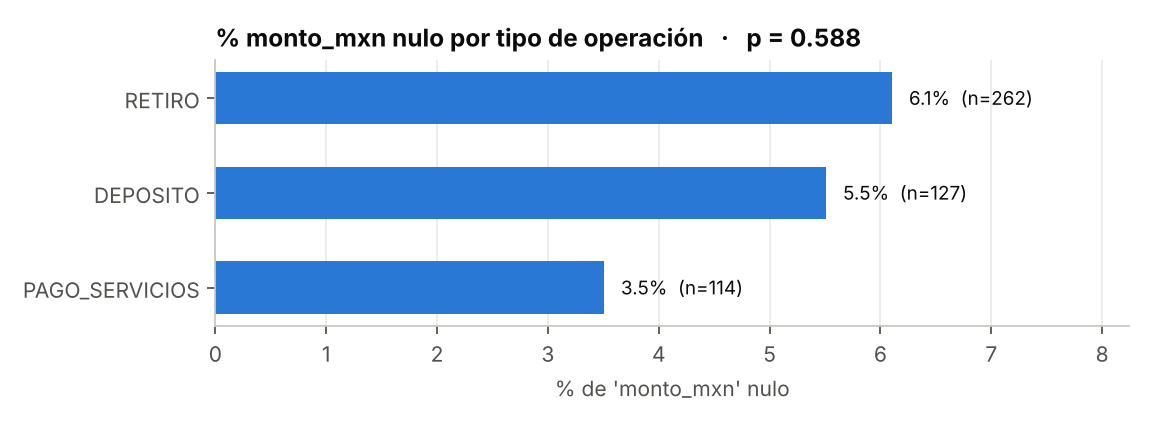

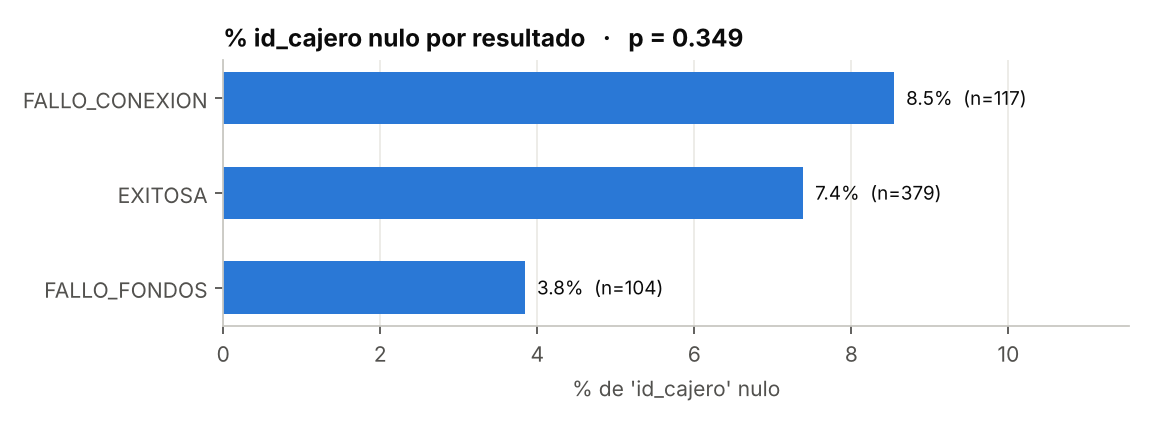

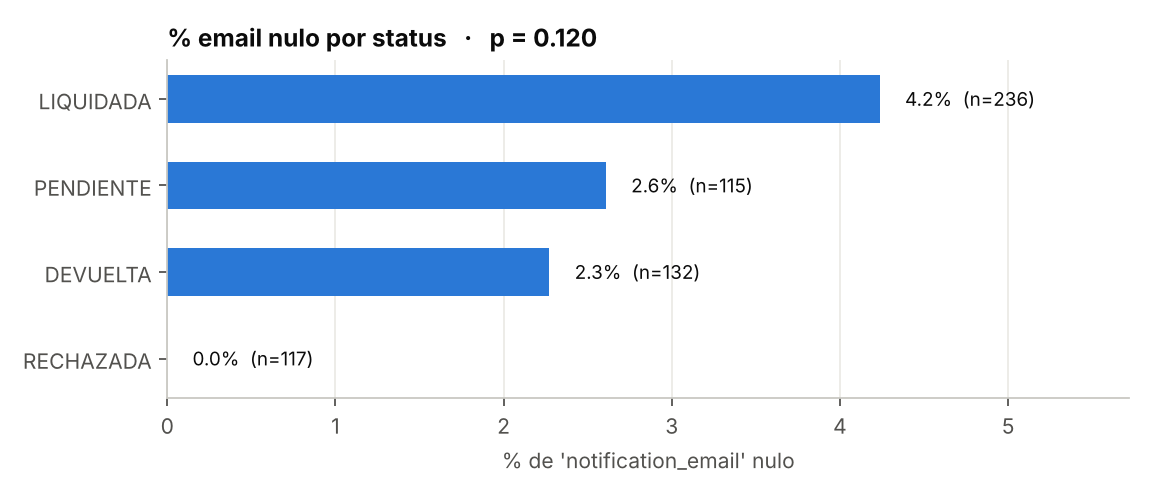

In [13]:
a_ded, _ = F2.eliminar_duplicados_exactos(F2.normalizar_etiquetas(seguro['transacciones_atm'], ['tipo_operacion','resultado']))
t_norm = F2.normalizar_etiquetas(seguro['transferencias_digitales'], ['status'])
pv = lambda v, e: float(pruebas[(pruebas.variable_con_nulos==v)&(pruebas.variable_explicativa==e)].p_valor.iloc[0])
FIG.tasa_nulos_por_grupo(a_ded[a_ded.tipo_operacion!='CONSULTA_SALDO'], 'monto_mxn', 'tipo_operacion',
                         '% monto_mxn nulo por tipo de operación', C.DIR_FIGURAS/'06_nulos_monto_por_tipo.png', pv('monto_mxn','tipo_operacion'))
FIG.tasa_nulos_por_grupo(a_ded, 'id_cajero', 'resultado', '% id_cajero nulo por resultado',
                         C.DIR_FIGURAS/'07_nulos_cajero_por_resultado.png', pv('id_cajero','resultado'))
FIG.tasa_nulos_por_grupo(t_norm, 'notification_email', 'status', '% email nulo por status',
                         C.DIR_FIGURAS/'08_nulos_email_por_status.png', pv('notification_email','status'))
for f in ['06_nulos_monto_por_tipo.png','07_nulos_cajero_por_resultado.png','08_nulos_email_por_status.png']:
    display(Image(str(C.DIR_FIGURAS/f)))

**Discusión MNAR (no comprobable con datos, se argumenta):**
* `monto_mxn`: sería MNAR si los montos grandes se perdieran más. Eso no se puede verificar (el monto es justo lo que falta), pero la falta no depende de `tipo_operacion`, `resultado`, `id_cajero` ni `comision_aplicada`, que sí están ligadas al monto; y en un cajero el monto lo registra el sistema, no el cliente → se descarta MNAR.
* `id_cajero`: el ID lo escribe la terminal, no el cliente; su ausencia es una falla de telemetría ajena al valor → MCAR.
* `notification_email`: el cliente simplemente no registró correo; no depende del monto ni del estado (p > 0.05) → MCAR.

#### Prueba de sensibilidad: ¿qué pasaría sin detectar los nulos disfrazados?

In [14]:
t_sin = F2.normalizar_etiquetas(ingenuo['transferencias_digitales'], ['status'])   # '' NO convertido a NaN
F2.clasificar_faltante(t_sin, 'notification_email', 'SPEI (solo null)', ['status'], [])[
    ['variable_con_nulos','n_nulos','variable_explicativa','brecha_pp','p_valor','conclusion']]

,variable_con_nulos,n_nulos,variable_explicativa,brecha_pp,p_valor,conclusion
0,notification_email,8,status,3.0,0.0342,MAR (depende de: status)


> Con solo los 8 `null` saldría **MAR por `status`** (conclusión falsa). Con los 16 ausentes reales la dependencia desaparece. Por eso los nulos disfrazados se tratan **antes** de clasificar.
### 2.2 ¿Por qué la mediana y no la media?

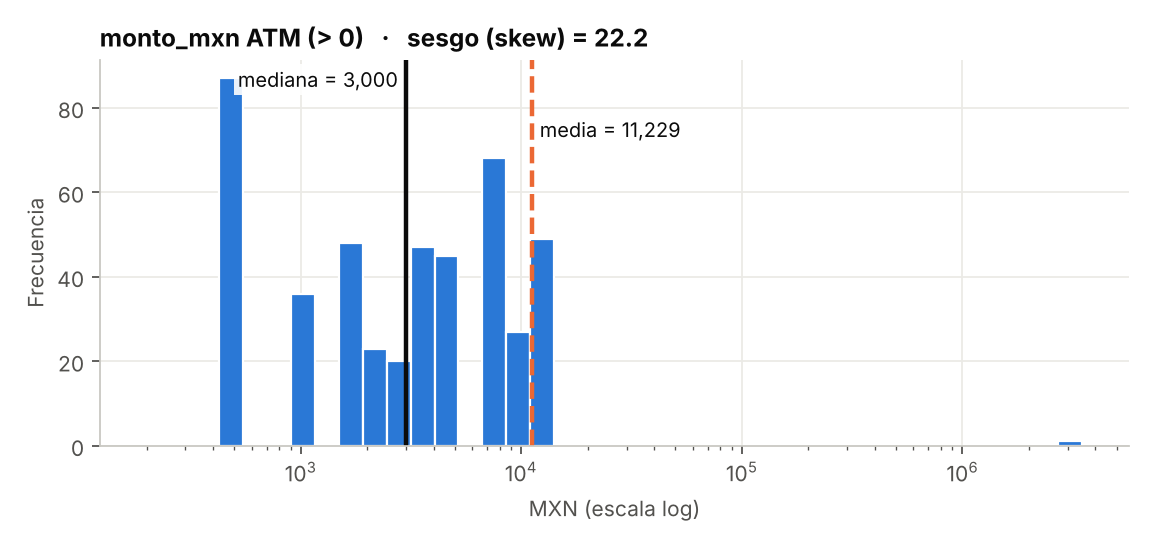

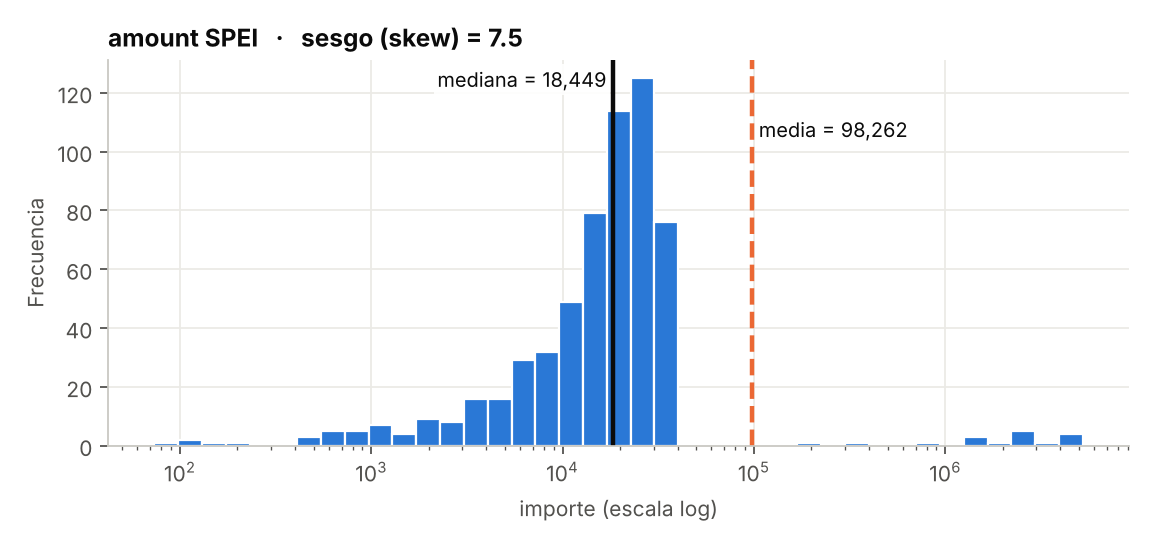

In [15]:
FIG.distribucion_sesgada(seguro['transacciones_atm']['monto_mxn'], 'monto_mxn ATM (> 0)', 'MXN', C.DIR_FIGURAS/'04_sesgo_monto_atm.png')
FIG.distribucion_sesgada(seguro['transferencias_digitales']['amount'], 'amount SPEI', 'importe', C.DIR_FIGURAS/'05_sesgo_amount_spei.png')
display(Image(str(C.DIR_FIGURAS/'04_sesgo_monto_atm.png'))); display(Image(str(C.DIR_FIGURAS/'05_sesgo_amount_spei.png')))

* `monto_mxn` tiene **sesgo = 22**: la media (≈ 11 229) queda arrastrada por un retiro de 3.5 M; la mediana (3 000) sí representa una operación típica.
* La mediana tiene **punto de ruptura del 50 %**; la media de **0 %** (un solo outlier la mueve).
### 2.3 ¿Mediana global (`SimpleImputer`, sesión 28) o mediana por grupo?

In [16]:
comp_si = F2.comparar_con_simpleimputer(a_ded)
display(comp_si)
print('Imputación categórica idéntica a SimpleImputer(strategy="constant"):', comp_si.attrs['categorica_equivalente'])

,tipo_operacion,nulos_a_imputar,mediana_global_SimpleImputer,mediana_por_grupo_pipeline,diferencia_mxn,media_del_grupo
0,DEPOSITO,7,3000.0,4000.0,1000.0,4741.67
1,PAGO_SERVICIOS,4,3000.0,4000.0,1000.0,5345.45
2,RETIRO,16,3000.0,2000.0,-1000.0,17488.62


Imputación categórica idéntica a SimpleImputer(strategy="constant"): True


> `SimpleImputer(strategy="median")` pondría **3 000** a todos. Pero un RETIRO típico es de 2 000 y un DEPÓSITO de 4 000, y la **media** de RETIRO es 17 489 por el outlier. Por eso se imputa con `groupby('tipo_operacion').median()`: es la misma idea de la mediana, aplicada dentro de cada tipo. Las banderas `<col>_imputado` cumplen la función de `add_indicator=True`.
### 2.4 Medianas usadas y bitácora (trazabilidad por registro)

In [17]:
display(pd.concat([med_atm.assign(variable='monto_mxn'), med_tr.assign(variable='amount')]))
bitacora = pd.concat([log_atm, log_tr], ignore_index=True)
display(bitacora.groupby(['dataset','columna','metodo']).size().rename('registros').reset_index())
bitacora.head(8)

,tipo_operacion,mediana,variable,currency
0,DEPOSITO,4000.000,monto_mxn,NaN
1,PAGO_SERVICIOS,4000.000,monto_mxn,NaN
2,RETIRO,2000.000,monto_mxn,NaN
0,NaN,18426.845,amount,MXN
1,NaN,19356.640,amount,USD


,dataset,columna,metodo,registros
0,transacciones_atm,id_cajero,ETIQUETA CONTROLADA 'CAJERO_DESCONOCIDO',42
1,transacciones_atm,monto_mxn,MEDIANA por tipo_operacion,27
2,transferencias_digitales,notification_email,ETIQUETA CONTROLADA 'ANONIMO',16


,dataset,id_registro,columna,valor_imputado,metodo,grupo
0,transacciones_atm,ATM-TX-00034,monto_mxn,4000.0,MEDIANA por tipo_operacion,PAGO_SERVICIOS
1,transacciones_atm,ATM-TX-00040,monto_mxn,4000.0,MEDIANA por tipo_operacion,PAGO_SERVICIOS
2,transacciones_atm,ATM-TX-00074,monto_mxn,2000.0,MEDIANA por tipo_operacion,RETIRO
3,transacciones_atm,ATM-TX-00075,monto_mxn,2000.0,MEDIANA por tipo_operacion,RETIRO
4,transacciones_atm,ATM-TX-00096,monto_mxn,2000.0,MEDIANA por tipo_operacion,RETIRO
5,transacciones_atm,ATM-TX-00113,monto_mxn,2000.0,MEDIANA por tipo_operacion,RETIRO
6,transacciones_atm,ATM-TX-00118,monto_mxn,4000.0,MEDIANA por tipo_operacion,DEPOSITO
7,transacciones_atm,ATM-TX-00162,monto_mxn,2000.0,MEDIANA por tipo_operacion,RETIRO


---
# Reporte comparativo de calidad · ANTES vs DESPUÉS

In [18]:
despues = {'catalogo_cuentas': seguro['catalogo_cuentas'], 'transacciones_atm': atm2, 'transferencias_digitales': tr2}
pc_d, pr_d = F1.perfil_completo({k: v[list(seguro[k].columns)] for k, v in despues.items()})
comp = perfil_cols[['dataset','columna','total_ausentes','pct_completitud']].merge(
    pc_d[['dataset','columna','total_ausentes','pct_completitud']], on=['dataset','columna'], suffixes=('_antes','_despues'))
display(comp[comp.total_ausentes_antes > 0])
pd.DataFrame({'dataset': perfil_res.dataset, 'filas_antes': perfil_res.filas, 'filas_despues': pr_d.filas,
              'completitud_antes_%': perfil_res.completitud_global_pct, 'completitud_despues_%': pr_d.completitud_global_pct,
              'duplicados_antes': perfil_res.duplicados_exactos, 'duplicados_despues': pr_d.duplicados_exactos})

,dataset,columna,total_ausentes_antes,pct_completitud_antes,total_ausentes_despues,pct_completitud_despues
10,transacciones_atm,monto_mxn,27,95.65,0,100.0
11,transacciones_atm,id_cajero,44,92.90,0,100.0
20,transferencias_digitales,notification_email,16,97.33,0,100.0


,dataset,filas_antes,filas_despues,completitud_antes_%,completitud_despues_%,duplicados_antes,duplicados_despues
0,catalogo_cuentas,50,50,100.00,100.0,0,0
1,transacciones_atm,620,600,98.57,100.0,20,0
2,transferencias_digitales,600,600,99.73,100.0,0,0


In [19]:
pd.concat([F2.estadisticos_antes_despues(seguro['transacciones_atm']['monto_mxn'], atm2['monto_mxn'], 'monto_mxn (ATM)'),
           F2.estadisticos_antes_despues(seguro['transferencias_digitales']['amount'], tr2['amount'], 'amount (SPEI)')])

,variable,etapa,n_no_nulos,nulos,media,mediana,desv_std,sesgo_skew,min,max
0,monto_mxn (ATM),antes (crudo),593,27,9316.53,1500.00,143637.62,24.33,0.00,3500000.0
1,monto_mxn (ATM),después (Fase 2),600,0,9225.33,1500.00,142797.13,24.47,0.00,3500000.0
0,amount (SPEI),antes (crudo),600,0,98261.81,18448.76,533615.81,7.47,73.62,5240100.0
1,amount (SPEI),después (Fase 2),600,0,98261.81,18448.76,533615.81,7.47,73.62,5240100.0


## Conclusiones
* Completitud ATM 98.57 % → **100 %**; SPEI 99.73 % → **100 %**; 20 reintentos eliminados; **ningún registro válido eliminado**.
* Las tres ausencias son **MCAR** (ninguna p < 0.05, nulidad no correlacionada, MNAR descartado por negocio).
* Numéricas sesgadas → **mediana por grupo**; categóricas → **etiquetas controladas** (`CAJERO_DESCONOCIDO`, `ANONIMO`); llaves nunca se imputan.
* La mediana de `monto_mxn` se mantiene en 1 500 MXN y la media cambia −1 %: la imputación no distorsiona la distribución.
* Salida para la Fase 3 / Ingeniero/a 2: `data/interim/*_fase2.*` (ejecutar `python run_ing1.py`).